# OPL segments: proofread vs predicted cell type

Predicted `celltype` = count/volume rules from `check_OPL_ribbons.ipynb`; `celltype_proofread` = manual tags from Spelunker.
Both columns are written by `evaluate_OPL_segments_proofread.py`.

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append("../utils")

import data_io
from style import set_rc_params

set_rc_params()

config = data_io.get_data_config()
version = config.get("version", None)
file_path = os.path.join(config["dataframes_dir"], config["file_opl_segments"])
assert os.path.exists(file_path), f"File not found: {file_path}"

fig_dir = f'../figures/connectivity/v{version}'
os.makedirs(fig_dir, exist_ok=True)

df = pd.read_csv(file_path, index_col=0)
df = df.astype({'cell': str})

# proofread candidates only (drops non-candidates and the untagged segments)
pr = df.dropna(subset=['celltype', 'celltype_proofread']).rename(
    columns={'celltype': 'predicted', 'celltype_proofread': 'proofread'})
pr['correct'] = pr['predicted'] == pr['proofread']
print(len(pr), 'proofread segments,', (~pr['correct']).sum(), 'misclassified')


1749 proofread segments, 178 misclassified


In [2]:
from matplotlib.lines import Line2D

palette = {
    'other':         '#888888',
    'rod':           '#3BD97C',
    'cone':          '#DB24E6',
    'mitochondrium': '#FFA500',
}
hue_order = ['rod', 'cone', 'mitochondrium', 'other']
markers = {'rod': 'o', 'cone': 's', 'other': '^'}
style_order = ['rod', 'cone', 'other']


def add_legend_rows(ax, rows, y0=-0.2, dy=0.09, max_per_row=3):
    """Legend below `ax`, one horizontal row per (title, handles, labels) group.
    Groups with more than `max_per_row` entries wrap onto further (column-aligned) rows."""
    blank = lambda: Line2D([], [], linestyle='')
    y = y0
    for title, handles, labels in rows:
        handles, labels = list(handles), list(labels)
        nrows = -(-len(handles) // max_per_row)
        ncol = -(-len(handles) // nrows)
        # pad to a full grid; legends fill column-major, so build columns explicitly
        handles += [blank()] * (nrows * ncol - len(handles))
        labels += [''] * (nrows * ncol - len(labels))
        H = [blank() for _ in range(nrows)]
        L = [title] + [''] * (nrows - 1)
        for col in range(ncol):
            for row in range(nrows):
                H.append(handles[row * ncol + col])
                L.append(labels[row * ncol + col])
        ax.figure.legend(H, L, ncol=ncol + 1, loc='upper left', bbox_to_anchor=(0, y),
                         bbox_transform=ax.transAxes, borderaxespad=0, handlelength=1.0,
                         columnspacing=1.0)
        y -= dy * nrows


def save(fig, name):
    fig.savefig(f'{fig_dir}/{name}.svg', bbox_inches='tight')
    fig.savefig(f'{fig_dir}/{name}.png', dpi=600, bbox_inches='tight')


## Joint plot: colour = proofread (true) type, marker = predicted type; misclassified points have a black edge

In [3]:
hue_order,markers,style_order

(['rod', 'cone', 'mitochondrium', 'other'],
 {'rod': 'o', 'cone': 's', 'other': '^'},
 ['rod', 'cone', 'other'])

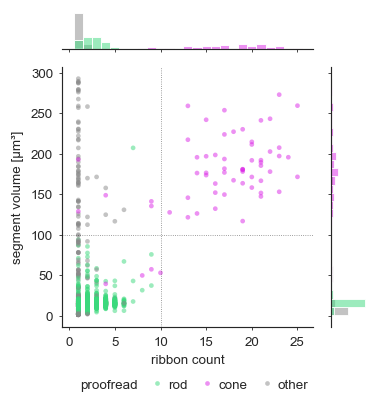

In [4]:
# mitochondria are shown as 'other' in this panel
pr['proofread_merged'] = pr['proofread'].replace({'mitochondrium': 'other'})
hue_order_merged = ['rod', 'cone', 'other']

g = sns.JointGrid(data=pr, x='count', y='volume_um3', height=3.2)


# correctly classified
sns.scatterplot(data=pr, x='count', y='volume_um3',
                hue='proofread_merged', hue_order=hue_order_merged, palette=palette, markers=markers,
                s=8,alpha = 0.5, linewidth=0, ax=g.ax_joint, legend=True)



# # correctly classified
# sns.scatterplot(data=pr[pr['correct']], x='count', y='volume_um3',
#                 hue='proofread_merged', hue_order=hue_order_merged, palette=palette,
#                 style='predicted', style_order=style_order, markers=markers,
#                 s=12, linewidth=0, ax=g.ax_joint, legend=False)
# # 
# # misclassified on top, with black edge (this call draws the legend, it contains all classes)
# sns.scatterplot(data=pr[~pr['correct']], x='count', y='volume_um3',
#                 hue='proofread_merged', hue_order=hue_order_merged, palette=palette,
#                 style='predicted', style_order=style_order, markers=markers,
#                 s=14, edgecolor='black', linewidth=0.4, zorder=4, ax=g.ax_joint, legend='full')

sns.histplot(data=pr, x='count', hue='proofread_merged', hue_order=hue_order_merged, ax=g.ax_marg_x,
             discrete=True, common_norm=False, stat='density',
             multiple='layer', palette=palette, legend=False)
sns.histplot(data=pr, y='volume_um3', hue='proofread_merged', hue_order=hue_order_merged, ax=g.ax_marg_y,
             binwidth=10, common_norm=False, stat='density',
             multiple='layer', palette=palette, legend=False)


g.ax_joint.axvline(x = 10, linestyle = ':', color = 'black', linewidth=0.5, zorder=3, alpha=0.5)
g.ax_joint.axhline(y = 100, linestyle = ':', color = 'black', linewidth=0.5, zorder=3, alpha=0.5)


# # example points
# sns.scatterplot(
#     df.query('cell.isin(["720575940559680500", "720575940558394587"])'),
#     x='count', y='volume_um3', color='#781A84', label='cone examples', marker='v',
#     s=25, edgecolor='black', linewidth=0.5, zorder=5, ax=g.ax_joint
# )
# sns.scatterplot(
#     df.query('cell.isin(["720575940548006929", "720575940547757073"])'),
#     x='count', y='volume_um3', color='#177A20', label='rod examples', marker='v',
#     s=25, edgecolor='black', linewidth=0.5, zorder=5, ax=g.ax_joint
# )

g.ax_joint.set_xlabel('ribbon count')
g.ax_joint.set_ylabel('segment volume [µm³]')

handles, labels = g.ax_joint.get_legend_handles_labels()
g.ax_joint.get_legend().remove()
g.figure.tight_layout()
add_legend_rows(g.ax_joint, [('proofread', handles, labels)])

save(g.figure, 'opl_segments_proofread_vs_predicted')

## Same plot, outlined by prediction outcome
Fill = proofread type (mitochondria shown as 'other'). Outline: **blue** = false negative (true rod/cone not predicted as that type),
**red** = false positive (predicted rod/cone, but proofread as a different type). Rod/cone swaps are both, so they get both outlines.

FP     False  True 
FN                 
False   1571    166
True       7      5


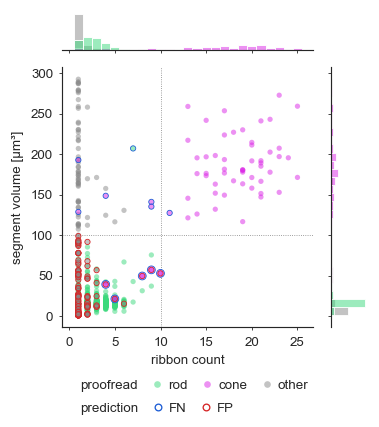

In [5]:
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D

photoreceptors = ['rod', 'cone']
# mitochondria are shown as 'other' in this panel
pr['proofread_merged'] = pr['proofread'].replace({'mitochondrium': 'other'})
hue_order_merged = ['rod', 'cone', 'other']
wrong = pr['predicted'] != pr['proofread_merged']
pr['FN'] = wrong & pr['proofread_merged'].isin(photoreceptors)  # true rod/cone missed
pr['FP'] = wrong & pr['predicted'].isin(photoreceptors)         # predicted rod/cone, but wrong
print(pd.crosstab(pr['FN'], pr['FP']).to_string())

outline = {'FN': '#1F5FD6', 'FP': '#D62728'}

g = sns.JointGrid(data=pr, x='count', y='volume_um3', height=3.2)

def fill(sub):
    return [to_rgba(palette[t], 0.5) for t in sub['proofread_merged']]

# correct: no outline
sub = pr[~pr['FN'] & ~pr['FP']]
g.ax_joint.scatter(sub['count'], sub['volume_um3'], s=10, zorder=2, facecolors=fill(sub), linewidths=0)
# FN: blue outline; rod/cone swaps get a larger blue ring underneath a red one
sub = pr[pr['FN']]
g.ax_joint.scatter(sub['count'], sub['volume_um3'], s=np.where(sub['FP'], 22, 10), zorder=3,
                   facecolors=fill(sub), edgecolors=outline['FN'], linewidths=0.5)
# FP: red outline
sub = pr[pr['FP']]
g.ax_joint.scatter(sub['count'], sub['volume_um3'], s=10, zorder=4,
                   facecolors=fill(sub), edgecolors=outline['FP'], linewidths=0.5)

sns.histplot(data=pr, x='count', hue='proofread_merged', hue_order=hue_order_merged, ax=g.ax_marg_x,
             discrete=True, common_norm=False, stat='density',
             multiple='layer', palette=palette, legend=False)
sns.histplot(data=pr, y='volume_um3', hue='proofread_merged', hue_order=hue_order_merged, ax=g.ax_marg_y,
             binwidth=10, common_norm=False, stat='density',
             multiple='layer', palette=palette, legend=False)

g.ax_joint.axvline(x = 10, linestyle = ':', color = 'black', linewidth=0.5, zorder=1, alpha=0.5)
g.ax_joint.axhline(y = 100, linestyle = ':', color = 'black', linewidth=0.5, zorder=1, alpha=0.5)

g.ax_joint.set_xlabel('ribbon count')
g.ax_joint.set_ylabel('segment volume [µm³]')

# legend below the panel: fill = proofread type, outline = prediction error
dot = dict(marker='o', linestyle='', markersize=4)
g.figure.tight_layout()
add_legend_rows(g.ax_joint, [
    ('proofread',
     [Line2D([], [], markerfacecolor=to_rgba(palette[t], 0.5), markeredgewidth=0, **dot) for t in hue_order_merged],
     hue_order_merged),
    ('prediction',
     [Line2D([], [], markerfacecolor='white', markeredgecolor=c, markeredgewidth=0.8, **dot) for c in outline.values()],
     list(outline)),
])

save(g.figure, 'opl_segments_proofread_vs_predicted_outlined')


## Same plot, marker shape by prediction outcome (alternative to the outlined version)
Mitochondria shown as 'other'. **Filled circle** = correct, **empty circle** = false negative (true rod/cone not predicted as that type),
**×** = false positive (predicted rod/cone, but proofread as a different type).
Circle colour = proofread (true) type, × colour = predicted type (the class it is a false positive for).
Rod/cone swaps are both a FN for the true class and a FP for the predicted class, so they get both: an empty circle in the
true-type colour with a × in the predicted-type colour (⊗).

correct: 1571   FN only: 7   FP only: 166   FN+FP (rod<->cone): 5


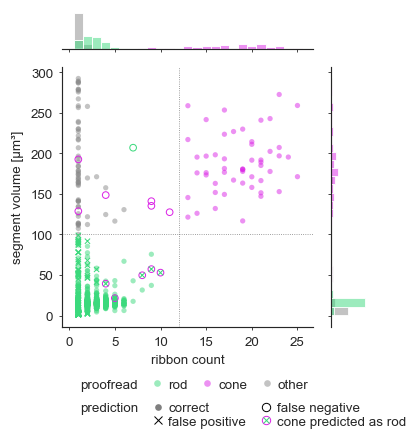

In [6]:
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D

photoreceptors = ['rod', 'cone']
# mitochondria are shown as 'other' in this panel
pr['proofread_merged'] = pr['proofread'].replace({'mitochondrium': 'other'})
hue_order_merged = ['rod', 'cone', 'other']
wrong = pr['predicted'] != pr['proofread_merged']
fn = wrong & pr['proofread_merged'].isin(photoreceptors)  # true rod/cone missed
fp = wrong & pr['predicted'].isin(photoreceptors)         # predicted rod/cone, but wrong
both = fn & fp                                            # rod <-> cone swaps
print(f"correct: {(~wrong).sum()}   FN only: {(fn & ~fp).sum()}   FP only: {(fp & ~fn).sum()}   FN+FP (rod<->cone): {both.sum()}")

g = sns.JointGrid(data=pr, x='count', y='volume_um3', height=3.2)
ax = g.ax_joint
s = 10

# correct: filled circle, colour = type
sub = pr[~wrong]
ax.scatter(sub['count'], sub['volume_um3'], s=s, marker='o', linewidths=0, zorder=2,
           c=[to_rgba(palette[t], 0.5) for t in sub['proofread_merged']])
# FN (incl. swaps): empty circle, colour = proofread type
sub = pr[fn]
ax.scatter(sub['count'], sub['volume_um3'], s=s * 1.6, marker='o', facecolors='none', linewidths=0.6, zorder=3,
           edgecolors=[palette[t] for t in sub['proofread_merged']])
# FP (incl. swaps): x, colour = predicted type
sub = pr[fp]
ax.scatter(sub['count'], sub['volume_um3'], s=s, marker='x', linewidths=0.6, zorder=4,
           c=[palette[t] for t in sub['predicted']])

sns.histplot(data=pr, x='count', hue='proofread_merged', hue_order=hue_order_merged, ax=g.ax_marg_x,
             discrete=True, common_norm=False, stat='density',
             multiple='layer', palette=palette, legend=False)
sns.histplot(data=pr, y='volume_um3', hue='proofread_merged', hue_order=hue_order_merged, ax=g.ax_marg_y,
             binwidth=10, common_norm=False, stat='density',
             multiple='layer', palette=palette, legend=False)

ax.axvline(x=12, linestyle=':', color='black', linewidth=0.5, zorder=1, alpha=0.5)
ax.axhline(y=100, linestyle=':', color='black', linewidth=0.5, zorder=1, alpha=0.5)
ax.set_xlabel('ribbon count')
ax.set_ylabel('segment volume [µm³]')

# legend below the panel: colour = type, marker = outcome
k = 'black'
type_handles = [Line2D([], [], marker='o', linestyle='', markersize=4, markeredgewidth=0,
                       markerfacecolor=to_rgba(palette[t], 0.5)) for t in hue_order_merged]
outcome_handles = [
    Line2D([], [], marker='o', linestyle='', markersize=4, markeredgewidth=0, markerfacecolor=to_rgba(k, 0.5)),
    Line2D([], [], marker='o', linestyle='', markersize=5, markeredgewidth=0.6,
           markerfacecolor='none', markeredgecolor=k),
    Line2D([], [], marker='x', linestyle='', markersize=5, markeredgewidth=0.6, color=k),
    (Line2D([], [], marker='o', linestyle='', markersize=5, markeredgewidth=0.6,
            markerfacecolor='none', markeredgecolor=palette['cone']),
     Line2D([], [], marker='x', linestyle='', markersize=4, markeredgewidth=0.6, color=palette['rod'])),
]
outcome_labels = ['correct', 'false negative', 'false positive', 'cone predicted as rod']

g.figure.tight_layout()
add_legend_rows(g.ax_joint, [('proofread', type_handles, hue_order_merged),
                             ('prediction', outcome_handles, outcome_labels)])

save(g.figure, 'opl_segments_proofread_vs_predicted_markers')


## Confusion matrix: predicted (rows) vs proofread (columns), counts and row-%

proofread,rod,cone,mitochondrium,other
predicted,,,,
rod,1456,5,60,106
cone,0,52,0,0
other,1,6,0,63


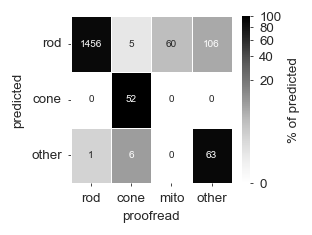

In [7]:
cm = pd.crosstab(pr['predicted'], pr['proofread']).reindex(index=style_order, columns=hue_order, fill_value=0)
cm_pct = cm.div(cm.sum(axis=1), axis=0) * 100
annot = cm.astype(str) #+ '\n(' + cm_pct.round(0).astype(int).astype(str) + '%)'

from matplotlib.colors import PowerNorm
# power-law color scale (gamma < 1) boosts contrast at low values while keeping 0 visible;
# lower gamma -> more contrast for small percentages (gamma=1 is linear)
norm = PowerNorm(gamma=0.3, vmin=0, vmax=100)

fig, ax = plt.subplots(figsize=(2.6, 2.0))
sns.heatmap(cm_pct, annot=annot, fmt='', cmap='Greys', norm=norm,
            cbar_kws={'label': '% of predicted'}, linewidths=0.5, linecolor='white',
            annot_kws={'fontsize': 6}, ax=ax)
ax.set_xlabel('proofread')
ax.set_ylabel('predicted')
ax.set_xticklabels(['rod', 'cone', 'mito','other'], rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
save(fig, 'opl_confusion_predicted_vs_proofread')
cm

## Summary (mitochondria count as a misclassification of the predicted class)

In [8]:
print(f"accuracy: {pr['correct'].mean():.3f}  ({pr['correct'].sum()}/{len(pr)})\n")
rows = []
for c in style_order:
    tp = ((pr['predicted'] == c) & (pr['proofread'] == c)).sum()
    rows.append({'class': c,
                 'n predicted': (pr['predicted'] == c).sum(),
                 'n proofread': (pr['proofread'] == c).sum(),
                 'precision': tp / (pr['predicted'] == c).sum(),
                 'recall': tp / (pr['proofread'] == c).sum()})
pd.DataFrame(rows).set_index('class').round(3)

accuracy: 0.898  (1571/1749)



,n predicted,n proofread,precision,recall
class,,,,
rod,1627,1457,0.895,0.999
cone,52,63,1.000,0.825
other,70,169,0.900,0.373
